<a href="https://colab.research.google.com/github/Kiiyoko123/well-free-acoustic-impedance-with-B-PINN/blob/main/Window_B_E2_E3_E4_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Second window: simpler geology (Marmousi2, 2D)

Robustness check of the first results (window A: x 5-12 km, complex faulted zone). Here **window B** is used: x 1-4.5 km, TWT 0.9-1.9 s, gently dipping layers. The same settings and the same tests are run, and both windows are reported.

Runs (seed 0, MAP and VI, ensemble skipped, about 10-15 min each, 5 runs plus the baseline, about 1-1.5 hours): baseline, E3 and E4 as below.

**E3**: the background (compaction trend) is wrong: shifted by +0.10 and -0.10 in ln Zp (about 10% impedance), and trend slope x1.3.
**E4**: the inversion assumes the wrong wavelet: data use 25 Hz, the inversion assumes 20 Hz or 30 Hz.

Compares MAP and VI (ensemble skipped, it halves the run time) against the correct-background, correct-wavelet case.

**How to run**
1. Upload the two unzipped Marmousi2 `.segy` files to the Files panel (left).
2. Check the names in the config cell (`VP_FILE`, `RHO_FILE`) match the Files panel exactly.
3. Runtime > Run all. Total about 1-1.5 hours on Colab CPU. Do not close the tab. Results are saved to `e34_summary.json` after every run.
4. Send the final table (printed at the end) back.

In [ ]:
!pip -q install segyio

In [ ]:
import argparse
import json
import os
import tarfile
import time
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter, gaussian_filter1d

torch.set_default_dtype(torch.float64)

MARMOUSI2_URL = ("https://s3.amazonaws.com/open.source.geoscience/open_data/"
                 "elastic-marmousi/elastic-marmousi-model.tar.gz")

## Definitions (do not edit)

In [ ]:
def get_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--model", choices=["auto", "real", "standin"], default="auto")
    p.add_argument("--model_dir", type=str, default="marmousi2_data",
                   help="folder holding (or receiving) the Marmousi2 SEG-Y files")
    p.add_argument("--vp_file", type=str, default=None,
                   help="your own Vp file (.segy/.sgy, .npy, .npz, .mat, or raw .bin/.dat float32)")
    p.add_argument("--rho_file", type=str, default=None,
                   help="your own density file; if omitted, rho = 310 Vp^0.25 (Gardner, kg/m3)")
    p.add_argument("--dz", type=float, default=1.25, help="depth sampling of your files (m)")
    p.add_argument("--dx", type=float, default=1.25, help="trace spacing of your files (m)")
    p.add_argument("--shape", type=int, nargs=2, default=None, metavar=("NZ", "NX"),
                   help="needed only for raw .bin/.dat files")
    p.add_argument("--transpose", choices=["auto", "yes", "no"], default="auto",
                   help="arrays must be (depth, x); auto flips if depth > x")
    p.add_argument("--n", type=int, default=250, help="samples per trace (coarse grid)")
    p.add_argument("--dt", type=float, default=0.004)
    p.add_argument("--fm", type=float, default=25.0, help="Ricker peak frequency, data (Hz)")
    p.add_argument("--fm_inv", type=float, default=None,
                   help="Ricker peak frequency used by the inversion (default = fm); E4")
    p.add_argument("--ntr", type=int, default=120)
    p.add_argument("--x0", type=float, default=4000.0, help="section start (m)")
    p.add_argument("--x1", type=float, default=10000.0, help="section end (m)")
    p.add_argument("--t_start", type=float, default=0.7, help="window start TWT (s)")
    p.add_argument("--noise", type=float, default=0.05, help="noise std / std(d) in the data")
    p.add_argument("--sigma_d_frac", type=float, default=0.10,
                   help="data tolerance in the likelihood, fraction of std(d)")
    p.add_argument("--bg", choices=["trend", "oracle", "regional"], default="trend",
                   help="trend = laterally constant linear trend; oracle = smoothed truth (upper bound)")
    p.add_argument("--ref_x0", type=float, default=500.0, help="with --bg regional: reference area (outside the window) start, m")
    p.add_argument("--ref_x1", type=float, default=4000.0, help="with --bg regional: reference area end, m")
    p.add_argument("--dil", type=str, default="1,1,1", help="CNN dilations of the 3 layers, e.g. 1,4,16 (wider receptive field)")
    p.add_argument("--tv", type=float, default=0.0, help="lateral total-variation penalty weight on delta ln Zp (0 = off)")
    p.add_argument("--sd_auto", action="store_true", help="estimate sigma_d from the MAP data residual (empirical Bayes) and refit")
    p.add_argument("--smooth_x", type=float, default=3.0,
                   help="with --bg oracle: lateral smoothing in traces (trace spacing = section length / ntr)")
    p.add_argument("--smooth_t", type=float, default=40.0,
                   help="with --bg oracle: smoothing in time samples (1 sample = dt)")
    p.add_argument("--bg_shift", type=float, default=0.0, help="add to m_LF (ln units); E3")
    p.add_argument("--bg_slope_scale", type=float, default=1.0, help="scale trend slope; E3")
    p.add_argument("--bg_unc", type=float, default=0.0,
                   help="prior std (ln Zp) of an unknown background shift, inferred jointly (0 = off)")
    p.add_argument("--slope_unc", type=float, default=0.0,
                   help="prior std of a relative error of the background slope, inferred jointly (0 = off)")
    p.add_argument("--fm_unc", type=float, default=0.0,
                   help="prior std (Hz) of the wavelet peak frequency around --fm_inv, inferred jointly (0 = off)")
    p.add_argument("--ch", type=int, default=8, help="CNN channels")
    p.add_argument("--k", type=int, default=11, help="CNN kernel size (odd)")
    p.add_argument("--sigma_p", type=float, default=0.1)
    p.add_argument("--n_ens", type=int, default=8)
    p.add_argument("--skip_ens", action="store_true", help="skip the deep ensemble (halves the run time)")
    p.add_argument("--map_steps", type=int, default=2000)
    p.add_argument("--vi_steps", type=int, default=3000)
    p.add_argument("--vi_mc", type=int, default=4)
    p.add_argument("--n_post", type=int, default=100)
    p.add_argument("--out", type=str, default="e2_out")
    p.add_argument("--quick", action="store_true")
    a = p.parse_args(argv)
    if a.fm_inv is None:
        a.fm_inv = a.fm
    if a.quick:
        a.map_steps, a.vi_steps, a.n_ens, a.n_post = 400, 800, 3, 30
    return a

In [ ]:
def load_marmousi2(model_dir):
    """Read Marmousi2 Vp (m/s) and density (kg/m3) on a 1.25 m grid. Downloads if needed."""
    import segyio
    d = Path(model_dir)
    d.mkdir(parents=True, exist_ok=True)
    vp_f = next(iter(d.rglob("*VELOCITY*1.25m*.segy")), None)
    rho_f = next(iter(d.rglob("*DENSITY*1.25m*.segy")), None)
    if vp_f is None or rho_f is None:
        tgz = d / "elastic-marmousi-model.tar.gz"
        if not tgz.exists():
            print(f"[model] downloading Marmousi2 (about 0.3 GB) ...")
            urllib.request.urlretrieve(MARMOUSI2_URL, tgz)
        with tarfile.open(tgz) as t:
            t.extractall(d)
        vp_f = next(iter(d.rglob("*VELOCITY*1.25m*.segy")))
        rho_f = next(iter(d.rglob("*DENSITY*1.25m*.segy")))

    def read(f):
        with segyio.open(str(f), "r", ignore_geometry=True) as s:
            return np.array(s.trace.raw[:], dtype=np.float32)  # (ntr, ns)

    vp, rho = read(vp_f).T, read(rho_f).T                    # -> (nz, nx)
    if vp.shape != rho.shape:
        raise RuntimeError(f"Vp {vp.shape} and density {rho.shape} shapes differ")
    print(f"[model] Marmousi2 read: nz={vp.shape[0]} nx={vp.shape[1]}  "
          f"Vp {vp.min():.0f}-{vp.max():.0f}, rho {rho.min():.2f}-{rho.max():.2f}")
    if vp.max() < 20:
        vp = vp * 1000.0
    if rho.max() < 20:
        rho = rho * 1000.0
    return vp, rho, 1.25, 1.25


def _read_array(path, shape=None):
    """Read one 2D array from .segy/.sgy, .npy, .npz, .mat or raw float32."""
    ext = Path(path).suffix.lower()
    if ext in (".segy", ".sgy"):
        import segyio
        with segyio.open(str(path), "r", ignore_geometry=True) as f:
            # NOTE: iterating f.trace re-uses one buffer in segyio (all traces get overwritten);
            # trace.raw[:] returns an independent copy of every trace.
            return np.array(f.trace.raw[:], dtype=np.float32).T                 # (ns, ntr)
    if ext == ".npy":
        return np.load(path)
    if ext == ".npz":
        z = np.load(path)
        return z[list(z.keys())[0]]
    if ext == ".mat":
        from scipy.io import loadmat
        m = loadmat(path)
        keys = [k for k in m if not k.startswith("__")]
        return np.asarray(m[keys[0]])
    if shape is None:
        raise ValueError("raw files need --shape NZ NX (rows, columns as stored)")
    return np.fromfile(path, dtype=np.float32).reshape(shape)


def load_user_model(a):
    vp = _read_array(a.vp_file, a.shape).astype(np.float32)
    if a.rho_file:
        rho = _read_array(a.rho_file, a.shape).astype(np.float32)
    else:
        print("[model] no density file: using rho = 310 * Vp^0.25 (Gardner)")
        rho = None
    if a.transpose == "yes" or (a.transpose == "auto" and vp.shape[0] > vp.shape[1]
                                and not str(a.vp_file).lower().endswith((".segy", ".sgy"))):
        vp = vp.T
        rho = rho.T if rho is not None else None
        print("[model] transposed to (depth, x)")
    if rho is not None and rho.shape != vp.shape:
        if rho.T.shape == vp.shape:
            rho = rho.T
        else:
            raise RuntimeError(f"Vp {vp.shape} and density {rho.shape} shapes differ")
    if vp.max() < 20:                       # km/s -> m/s
        vp = vp * 1000.0
    if rho is None:
        rho = 310.0 * vp.astype(np.float64) ** 0.25
    elif rho.max() < 20:                    # g/cc -> kg/m3
        rho = rho * 1000.0
    print(f"[model] your files: nz={vp.shape[0]} nx={vp.shape[1]}  dz={a.dz} m dx={a.dx} m  "
          f"Vp {vp.min():.0f}-{vp.max():.0f} m/s  rho {rho.min():.0f}-{rho.max():.0f} kg/m3  "
          f"depth {vp.shape[0] * a.dz:.0f} m  width {vp.shape[1] * a.dx:.0f} m")
    return vp, rho, a.dz, a.dx


def standin_marmousi_like(seed=123, nz=700, nx=1400, dz=5.0, dx=12.5):
    """Marmousi-like stand-in: dipping, folded, faulted thin layers; water layer on top.
    NOT Marmousi2. Used only to test the pipeline when the real model is unreachable."""
    rng = np.random.default_rng(seed)
    z = np.arange(nz)[:, None] * dz
    x = np.arange(nx)[None, :] * dx
    s = z - 450.0
    s = s + 260 * np.sin(2 * np.pi * x / 7000.0) * np.exp(-np.clip(s, 0, None) / 2500.0)
    s = s + 0.10 * (x - 9000.0)
    s = s + 120.0 * (x > 6200) * (1 + 0.0 * z) - 90.0 * (x > 12000)
    edges = np.cumsum(rng.uniform(15, 70, 400))
    pert = rng.normal(0, 260, 401)
    pert[rng.random(401) < 0.08] -= 650                       # gas-sand-like lows
    idx = np.searchsorted(edges, np.clip(s, 0, None))
    vp = 1800.0 + 0.62 * np.clip(s, 0, None) + pert[idx]
    vp = np.clip(vp, 1600, 5200)
    rho = 310.0 * vp ** 0.25 * (1 + rng.normal(0, 0.0, 1)) + 40 * pert[idx] / 260
    water = z < 450.0 + 0 * x                                 # flat water layer only
    vp = np.where(water, 1500.0, vp)
    rho = np.where(water, 1000.0, rho)
    return vp, rho, dz, dx


def depth_to_time(vp, rho, dz, dtf, t_start, nf):
    """vp, rho: (nz, ntr). Returns Zp (ntr, nf) in MRayl on a uniform TWT grid."""
    zp = vp * rho / 1e6
    twt = 2.0 * np.cumsum(dz / vp, axis=0)
    t_axis = t_start + np.arange(nf) * dtf
    if twt[-1].min() < t_axis[-1]:
        raise RuntimeError("model too shallow for the requested time window")
    return np.stack([np.interp(t_axis, twt[:, j], zp[:, j]) for j in range(vp.shape[1])])


def load_any(a):
    src = a.model
    vp = rho = None
    if a.vp_file:
        vp, rho, dz, dx = load_user_model(a)
        src_used = "Marmousi2 (user files)"
        src = "user"
    if src in ("auto", "real"):
        try:
            vp, rho, dz, dx = load_marmousi2(a.model_dir)
            src_used = "Marmousi2"
        except Exception as e:  # noqa
            if src == "real":
                raise
            print(f"[model] real Marmousi2 unavailable ({type(e).__name__}: {str(e)[:80]}).")
    if vp is None:
        print("[model] *** USING THE MARMOUSI-LIKE STAND-IN, NOT MARMOUSI2 ***")
        vp, rho, dz, dx = standin_marmousi_like()
        src_used = "stand-in"
    return vp, rho, dz, dx, src_used


def preview_model(a, step_m=25.0):
    """Plot Zp (MRayl) of the WHOLE model in two-way time, with the chosen window boxed.
    Use it to choose --x0/--x1/--t_start before the long run."""
    vp, rho, dz, dx, src_used = load_any(a)
    st = max(1, int(round(step_m / dx)))
    cols = np.arange(0, vp.shape[1], st)
    dtp = 0.004
    nt = int(min(2.0 * np.sum(dz / vp[:, cols], axis=0).min(), 4.0) / dtp)
    zt = depth_to_time(vp[:, cols].astype(np.float64), rho[:, cols].astype(np.float64),
                       dz, dtp, 0.0, nt)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    h = ax[0].imshow((vp * rho / 1e6)[::max(1, int(10 / dz)), ::max(1, int(25 / dx))],
                     aspect="auto", cmap="viridis",
                     extent=[0, vp.shape[1] * dx / 1000, vp.shape[0] * dz / 1000, 0])
    ax[0].set_title(f"Zp in depth ({src_used})"); ax[0].set_xlabel("x (km)"); ax[0].set_ylabel("depth (km)")
    plt.colorbar(h, ax=ax[0])
    h = ax[1].imshow(zt.T, aspect="auto", cmap="viridis",
                     extent=[0, vp.shape[1] * dx / 1000, nt * dtp, 0])
    t1 = a.t_start + a.n * a.dt
    ax[1].plot([a.x0 / 1000, a.x1 / 1000, a.x1 / 1000, a.x0 / 1000, a.x0 / 1000],
               [a.t_start, a.t_start, t1, t1, a.t_start], "r", lw=2)
    ax[1].set_title("Zp in TWT; red box = window the inversion will use")
    ax[1].set_xlabel("x (km)"); ax[1].set_ylabel("TWT (s)")
    plt.colorbar(h, ax=ax[1])
    fig.tight_layout()
    Path(a.out).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(a.out) / "e2_model_preview.png", dpi=110)
    plt.show()
    print(f"[preview] x {a.x0:.0f}-{a.x1:.0f} m, TWT {a.t_start:.2f}-{t1:.2f} s")


def get_truth(a):
    nf = 2 * a.n
    dtf = a.dt / 2.0
    vp, rho, dz, dx, src_used = load_any(a)
    width = vp.shape[1] * dx
    x0, x1 = a.x0, a.x1
    if x1 > width or x0 >= x1:
        x0, x1 = 0.05 * width, 0.95 * width
        print(f"[model] requested x-range outside the model ({width:.0f} m wide); "
              f"using {x0:.0f}-{x1:.0f} m")
    i0, i1 = int(x0 / dx), int(x1 / dx)
    cols = np.linspace(i0, i1 - 1, a.ntr).astype(int)
    vp_s, rho_s = vp[:, cols].astype(np.float64), rho[:, cols].astype(np.float64)
    # refine in depth if coarse (keeps TWT integration accurate)
    mid = vp_s[:, len(cols) // 2]
    sea = 2.0 * float(np.sum(dz / mid[mid <= 1510])) if (mid <= 1510).any() else 0.0
    twt_max = float(2.0 * np.sum(dz / vp_s, axis=0).min())
    print(f"[model] water column about {sea:.2f} s TWT; model reaches {twt_max:.2f} s; "
          f"window {a.t_start:.2f}-{a.t_start + a.n * a.dt:.2f} s")
    if a.t_start < sea:
        print("[model] WARNING: window starts inside the water layer; raise --t_start")
    z_fine = depth_to_time(vp_s, rho_s, dz, dtf, a.t_start, nf)
    return z_fine, src_used, cols * dx

In [ ]:
def ricker(t, fm):
    a = (np.pi * fm * t) ** 2
    return (1.0 - 2.0 * a) * np.exp(-a)


def synth_data_fine(z_fine, dt, fm, half=0.064):
    """Data operator on the FINE grid, vectorised over traces (axis 1 = time)."""
    dtf = dt / 2.0
    m = np.log(z_fine)
    r = np.zeros_like(m)
    r[:, 1:-1] = 0.25 * (m[:, 2:] - m[:, :-2])
    kf = int(round(half / dtf))
    w = ricker(np.arange(-kf, kf + 1) * dtf, fm)
    d = np.stack([np.convolve(r[i], w, mode="same") for i in range(r.shape[0])])
    return d[:, ::2]


def build_G(n, dt, fm, half=0.064):
    """Inversion operator on the COARSE grid, G = C D, as an n x n matrix."""
    D = np.zeros((n, n))
    for i in range(1, n - 1):
        D[i, i - 1], D[i, i + 1] = -0.25, 0.25
    k = int(round(half / dt))
    w = ricker(np.arange(-k, k + 1) * dt, fm)
    C = np.zeros((n, n))
    for i in range(n):
        for j in range(max(0, i - k), min(n, i + k + 1)):
            C[i, j] = w[(i - j) + k]
    return torch.tensor(C @ D)


def build_G_t(n, dt, fm, D, half=0.064):
    """Differentiable version of build_G (fm may be a tensor): G = C(fm) D."""
    k = int(round(half / dt))
    tk = torch.arange(-k, k + 1, dtype=torch.float64) * dt
    aa = (np.pi * fm * tk) ** 2
    w = (1.0 - 2.0 * aa) * torch.exp(-aa)
    idx = torch.arange(n)[:, None] - torch.arange(n)[None, :] + k
    ok = (idx >= 0) & (idx <= 2 * k)
    C = torch.where(ok, w[idx.clamp(0, 2 * k)], torch.zeros((), dtype=torch.float64))
    return C @ D

In [ ]:
class CNN1D:
    """Three-layer 1D CNN, flat parameter vector. Shared by every trace."""

    def __init__(self, ch, k, dil=(1, 1, 1)):
        self.k = k
        self.dil = tuple(dil)
        self.shapes = [(ch, 1, k), (ch,), (ch, ch, k), (ch,), (1, ch, k), (1,)]
        self.sizes = [int(np.prod(s)) for s in self.shapes]
        self.P = sum(self.sizes)

    def unpack(self, th):
        out, i = [], 0
        for s, n in zip(self.shapes, self.sizes):
            out.append(th[i:i + n].view(*s))
            i += n
        return out

    def __call__(self, th, x):                      # x: (ntr, 1, n)
        W1, b1, W2, b2, W3, b3 = self.unpack(th)
        p = self.k // 2
        d1, d2, d3 = self.dil
        h = torch.tanh(F.conv1d(x, W1, b1, padding=p * d1, dilation=d1))
        h = torch.tanh(F.conv1d(h, W2, b2, padding=p * d2, dilation=d2))
        return F.conv1d(h, W3, b3, padding=p * d3, dilation=d3)[:, 0, :]


class Problem:
    """Misfit/prior for theta = [CNN weights, optional nuisance parameters].
    Nuisance parameters (each only if its prior std > 0):
      b : background shift (ln Zp)            m_LF -> m_LF + b
      u : relative background slope error     m_LF -> m_LF + u * (m_LF - mean(m_LF))
      f : wavelet peak-frequency offset (Hz)  G built with fm0 + f
    Their priors are centred on the supplied (possibly wrong) values, with the stated std."""

    def __init__(self, net, G, d_obs, m_lf, x_in, sigma_d, sigma_p, unc=None, fm0=None, dt=None, n=None):
        self.net, self.G, self.d, self.m_lf, self.x = net, G, d_obs, m_lf, x_in
        self.sd, self.sp = sigma_d, sigma_p
        self.tv = 0.0
        self.Pn = net.P
        unc = unc or {}
        self.keys = [k for k in ("b", "u", "f") if unc.get(k, 0) > 0]
        self.P = net.P + len(self.keys)
        sp = torch.full((self.P,), float(sigma_p))
        self.unc = {k: float(unc[k]) for k in self.keys}
        for j, k in enumerate(self.keys):
            sp[net.P + j] = 1.0              # nuisance parameters are stored standardised: value = std * z, z ~ N(0,1)
        self.sp_vec = sp
        self.fm0, self.dt, self.n = fm0, dt, n
        if "f" in self.keys:
            D = np.zeros((n, n))
            for i in range(1, n - 1):
                D[i, i - 1], D[i, i + 1] = -0.25, 0.25
            self.D = torch.tensor(D)

    def _ex(self, th):
        out = {"b": 0.0, "u": 0.0, "f": None}
        for j, k in enumerate(self.keys):
            out[k] = th[self.Pn + j] * self.unc[k]
        return out

    def operator(self, th):
        e = self._ex(th)
        if e["f"] is None:
            return self.G
        return build_G_t(self.n, self.dt, self.fm0 + e["f"], self.D)

    def base(self):
        return self.m_lf if self.m_lf.ndim == 2 else self.m_lf[None, :]

    def base_eff(self, th):
        e = self._ex(th)
        b = self.base()
        return b + e["b"] + e["u"] * (b - b.mean(-1, keepdim=True))

    def delta_m(self, th):
        return self.net(th[:self.Pn], self.x)

    def misfit(self, th):
        m = self.base_eff(th) + self.delta_m(th)
        r = self.d - m @ self.operator(th).T
        out = 0.5 * (r ** 2).sum() / self.sd ** 2
        if self.tv > 0:
            dm = self.delta_m(th)
            out = out + self.tv * torch.sqrt((dm[1:] - dm[:-1]) ** 2 + 1e-4).sum()
        return out

    def U(self, th):
        return self.misfit(th) + 0.5 * ((th / self.sp_vec) ** 2).sum()

    def zp_log(self, th):
        return self.base_eff(th) + self.delta_m(th)

    def zp(self, th):
        return torch.exp(self.base_eff(th) + self.delta_m(th))

In [ ]:
def fit_map(pb, theta0, steps, lr=1e-2, prior=True, wd=0.0):
    th = theta0.clone().requires_grad_(True)
    opt = torch.optim.Adam([th], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        opt.zero_grad()
        loss = pb.U(th) if prior else pb.misfit(th) + wd * (th ** 2).sum()
        loss.backward()
        opt.step()
        sched.step()
    return th.detach()


def fit_vi(pb, steps, mc, lr=3e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    P, sp = pb.P, pb.sp_vec
    mu0 = torch.randn(P, generator=g) * 0.1
    mu0[pb.Pn:] = 0.0
    mu = mu0.requires_grad_(True)
    rho = torch.full((P,), -4.0, requires_grad=True)
    opt = torch.optim.Adam([mu, rho], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist = []
    for it in range(steps):
        opt.zero_grad()
        s = F.softplus(rho)
        data = 0.0
        for _ in range(mc):
            data = data + pb.misfit(mu + s * torch.randn(P, generator=g))
        data = data / mc
        kl = (torch.log(sp / s) + (s ** 2 + mu ** 2) / (2 * sp ** 2) - 0.5).sum()
        (data + kl).backward()
        opt.step()
        sched.step()
        if it % max(1, steps // 20) == 0:
            hist.append((it, float(data.detach()), float(kl.detach())))
    return mu.detach(), F.softplus(rho).detach(), hist

In [ ]:
LEVELS = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95])


def point_metrics(pred, truth, m_lf=None):
    sse = float(((pred - truth) ** 2).sum())
    sst = float(((truth - truth.mean()) ** 2).sum())
    out = dict(corr=float(np.corrcoef(pred.ravel(), truth.ravel())[0, 1]),
               r2=1.0 - sse / sst,
               mae=float(np.mean(np.abs(pred - truth))))
    if m_lf is not None:                     # skill beyond the background, in ln Zp
        dp, dt_ = np.log(pred) - m_lf, np.log(truth) - m_lf
        out["corr_resid"] = (float(np.corrcoef(dp.ravel(), dt_.ravel())[0, 1])
                             if dp.std() > 1e-9 else 0.0)
    # band-limited skill: seismic only contains the high-frequency part of ln Zp
    hp = lambda A: np.log(A) - gaussian_filter1d(np.log(A), 10, axis=1)   # noqa
    out["corr_hp"] = float(np.corrcoef(hp(pred).ravel(), hp(truth).ravel())[0, 1])
    lp = lambda A: gaussian_filter1d(np.log(A), 10, axis=1)               # noqa
    out["corr_lp"] = float(np.corrcoef(lp(pred).ravel(), lp(truth).ravel())[0, 1])
    return out


def summarize(z_samp, z_true, m_lf):
    """z_samp: (S, ntr, n)."""
    mean = z_samp.mean(0)
    lo, hi = np.quantile(z_samp, [0.05, 0.95], axis=0)
    cov = {}
    for lv in LEVELS:
        aa = (1 - lv) / 2
        l, h = np.quantile(z_samp, [aa, 1 - aa], axis=0)
        cov[float(lv)] = float(np.mean((z_true >= l) & (z_true <= h)))
    r = point_metrics(mean, z_true, m_lf)
    r.update(picp90=cov[0.9], width90=float(np.mean(hi - lo)), coverage=cov)
    return r, mean, lo, hi, z_samp.std(0)

In [ ]:
def run(a):
    out = Path(a.out)
    out.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(a.seed)
    torch.manual_seed(a.seed)
    n = a.n

    z_fine, src_used, xs = get_truth(a)
    z_true = z_fine[:, ::2].copy()                                  # (ntr, n) MRayl
    d = synth_data_fine(z_fine, a.dt, a.fm)
    sd_clean = d.std()
    d = d + a.noise * sd_clean * rng.standard_normal(d.shape)
    G = build_G(n, a.dt, a.fm_inv)
    G_true = build_G(n, a.dt, a.fm)

    m_true = np.log(z_true)
    tt = np.arange(n)
    if a.bg == "trend":
        coef = np.polyfit(np.tile(tt, m_true.shape[0]), m_true.ravel(), 1)
        coef[0] *= a.bg_slope_scale
        m_lf = np.polyval(coef, tt) + a.bg_shift
    elif a.bg == "regional":
        import copy
        ar = copy.copy(a); ar.x0, ar.x1 = a.ref_x0, a.ref_x1
        zr, _, _ = get_truth(ar)
        mr = np.log(zr[:, ::2])
        coef = np.polyfit(np.tile(tt, mr.shape[0]), mr.ravel(), 1)
        coef[0] *= a.bg_slope_scale
        m_lf = np.polyval(coef, tt) + a.bg_shift
        print(f"[bg   ] regional trend fitted OUTSIDE the window (x {a.ref_x0:.0f}-{a.ref_x1:.0f} m)")
    else:
        m_lf = gaussian_filter(m_true, (a.smooth_x, a.smooth_t)) + a.bg_shift   # (ntr, n), uses the truth
    m_lf_t = torch.tensor(m_lf)
    mlf_plot = m_lf if m_lf.ndim == 2 else np.tile(m_lf, (m_true.shape[0], 1))

    d_t = torch.tensor(d)
    sd_d = float(d_t.std())
    sigma_d = a.sigma_d_frac * sd_d
    mis = float(torch.linalg.norm(d_t - torch.tensor(m_true) @ G.T) / torch.linalg.norm(d_t))
    print(f"[model] {src_used}: {z_true.shape[0]} traces x {n} samples, "
          f"Zp {z_true.min():.1f}-{z_true.max():.1f} MRayl")
    print(f"[data ] std(d)={sd_d:.4f} noise={a.noise:.2f}*std  sigma_d={sigma_d:.4f}  "
          f"operator mismatch={mis:.3f}")

    net = CNN1D(a.ch, a.k, [int(v) for v in a.dil.split(",")])
    x_in = (d_t / sd_d)[:, None, :]
    mlf_for_pb = m_lf_t if m_lf_t.ndim == 1 else torch.tensor(m_lf)
    unc = {"b": a.bg_unc, "u": a.slope_unc, "f": a.fm_unc}
    pb = Problem(net, G, d_t, mlf_for_pb, x_in, sigma_d, a.sigma_p, unc=unc,
                 fm0=a.fm_inv, dt=a.dt, n=n)
    if pb.keys:
        print(f"[nuis ] jointly inferred nuisance parameters {pb.keys} with prior std "
              f"{[unc[k] for k in pb.keys]}  (ensemble is skipped in this mode)")
        a.skip_ens = True

    pb.tv = a.tv
    gp = torch.Generator().manual_seed(a.seed + 99)
    pr = torch.stack([pb.delta_m(torch.randn(net.P, generator=gp) * a.sigma_p)
                      for _ in range(30)])
    print(f"[net  ] parameters={net.P}   prior-predictive std(delta ln Zp)={float(pr.std()):.3f}")

    results, means, bands, stds = {}, {}, {}, {}
    t0 = time.time()
    bgz = np.exp(mlf_plot)
    results["Background"] = point_metrics(bgz, z_true, mlf_plot)
    print(f"[BG   ] corr={results['Background']['corr']:.3f} R2={results['Background']['r2']:.3f} "
          f"MAE={results['Background']['mae']:.3f}")

    th0 = torch.randn(pb.P) * pb.sp_vec
    th0[pb.Pn:] = 0.0
    th_map = fit_map(pb, th0, a.map_steps, prior=True)
    if a.sd_auto:
        with torch.no_grad():
            rr = d_t - pb.zp_log(th_map) @ pb.operator(th_map).T
        sd_new = float(rr.std())
        print(f"[cal  ] sigma_d from MAP residual: {sd_new:.4f} (was {pb.sd:.4f}); refitting")
        pb.sd = sd_new
        results["sigma_d_auto"] = sd_new
        th_map = fit_map(pb, th_map, a.map_steps, prior=True)
    z_map = pb.zp(th_map).numpy()
    results["MAP"] = point_metrics(z_map, z_true, mlf_plot)
    results["MAP"]["misfit_nll"] = float(pb.misfit(th_map))
    print(f"[MAP  ] corr={results['MAP']['corr']:.3f} R2={results['MAP']['r2']:.3f} "
          f"MAE={results['MAP']['mae']:.3f} resid-corr={results['MAP']['corr_resid']:.3f} "
          f"({time.time() - t0:.0f}s)")

    mu, s, hist = fit_vi(pb, a.vi_steps, a.vi_mc, seed=a.seed)
    gd = torch.Generator().manual_seed(a.seed + 1)
    z_vi = np.stack([pb.zp(mu + s * torch.randn(pb.P, generator=gd)).numpy()
                     for _ in range(a.n_post)])
    for j, k in enumerate(pb.keys):
        m_, s_ = float(mu[pb.Pn + j]) * unc[k], float(s[pb.Pn + j]) * unc[k]
        shown = f"{a.fm_inv + m_:.2f} +- {s_:.2f} Hz (assumed {a.fm_inv:.1f})" if k == "f" \
            else f"{m_:+.3f} +- {s_:.3f}"
        print(f"[VI   ] nuisance {k}: posterior {shown}   prior std {unc[k]}")
        results.setdefault("nuisance", {})[k] = dict(mean=m_, std=s_, prior_std=unc[k])
    results["VI"], means["VI"], lo, hi, sdv = summarize(z_vi, z_true, mlf_plot)
    bands["VI"], stds["VI"] = (lo, hi), sdv
    results["VI"]["elbo_history(it,data,kl)"] = hist
    results["VI"]["mean_weight_std"] = float(s.mean())
    print(f"[VI   ] corr={results['VI']['corr']:.3f} R2={results['VI']['r2']:.3f} "
          f"MAE={results['VI']['mae']:.3f} resid-corr={results['VI']['corr_resid']:.3f} "
          f"PICP90={results['VI']['picp90']:.2f} width90={results['VI']['width90']:.2f} "
          f"({time.time() - t0:.0f}s)")

    if not a.skip_ens:
        z_ens = []
        for e in range(a.n_ens):
            g = torch.Generator().manual_seed(1000 + 100 * a.seed + e)
            thi = torch.randn(net.P, generator=g) * a.sigma_p
            z_ens.append(pb.zp(fit_map(pb, thi, a.map_steps, prior=False, wd=1e-4)).numpy())
        z_ens = np.stack(z_ens)
        results["Ensemble"], means["Ensemble"], lo, hi, sde = summarize(z_ens, z_true, mlf_plot)
        bands["Ensemble"], stds["Ensemble"] = (lo, hi), sde
        print(f"[ENS  ] corr={results['Ensemble']['corr']:.3f} R2={results['Ensemble']['r2']:.3f} "
              f"MAE={results['Ensemble']['mae']:.3f} resid-corr={results['Ensemble']['corr_resid']:.3f} "
              f"PICP90={results['Ensemble']['picp90']:.2f} width90={results['Ensemble']['width90']:.2f} "
              f"({time.time() - t0:.0f}s)")

    # does the uncertainty point at the errors?  (rank correlation of std and |error|)
    from scipy.stats import spearmanr
    for k in [m_ for m_ in ["VI", "Ensemble"] if m_ in means]:
        err = np.abs(means[k] - z_true).ravel()
        results[k]["spearman_std_vs_abs_err"] = float(spearmanr(stds[k].ravel(), err)[0])

    results["setup"] = dict(vars(a), source=src_used, sigma_d=sigma_d, operator_mismatch=mis,
                            n_params=net.P)
    with open(out / "e2_results.json", "w") as f:
        json.dump(results, f, indent=2)
    arrs = dict(z_true=z_true, d=d, z_map=z_map, z_vi_mean=means["VI"], z_vi_std=stds["VI"],
                m_lf=mlf_plot, x=xs)
    if "Ensemble" in means:
        arrs.update(z_ens_mean=means["Ensemble"], z_ens_std=stds["Ensemble"])
    np.savez(out / "e2_arrays.npz", **arrs)

    # ---- figures
    t_ms = (a.t_start + np.arange(n) * a.dt) * 1000
    ext = [xs[0] / 1000, xs[-1] / 1000, t_ms[-1], t_ms[0]]
    vmin, vmax = np.percentile(z_true, [1, 99])

    def im(ax, A, title, cmap="viridis", vmin=None, vmax=None):
        h = ax.imshow(A.T, aspect="auto", extent=ext, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("x (km)")
        ax.set_ylabel("TWT (ms)")
        plt.colorbar(h, ax=ax, fraction=0.04)

    fig, ax = plt.subplots(2, 4, figsize=(20, 8))
    ax = ax.ravel()
    im(ax[0], z_true, "True Zp (MRayl)", vmin=vmin, vmax=vmax)
    im(ax[1], bgz, f"Background ({a.bg})", vmin=vmin, vmax=vmax)
    im(ax[2], d, "Seismic (post-stack, noisy)", "gray")
    im(ax[3], z_map, f"MAP corr={results['MAP']['corr']:.2f}", vmin=vmin, vmax=vmax)
    im(ax[4], means["VI"], f"VI mean corr={results['VI']['corr']:.2f}", vmin=vmin, vmax=vmax)
    im(ax[5], stds["VI"], "VI posterior std (MRayl)", "magma")
    im(ax[6], np.abs(means["VI"] - z_true), "VI |error| (MRayl)", "magma")
    if "Ensemble" in stds:
        im(ax[7], stds["Ensemble"], "Ensemble std (MRayl)", "magma")
    else:
        ax[7].axis("off")
    fig.tight_layout()
    fig.savefig(out / "e2_sections.png", dpi=130)

    j = z_true.shape[0] // 2
    fig2, ax2 = plt.subplots(1, 2, figsize=(13, 5))
    ax2[0].step(t_ms, z_true[j], "k", where="mid", label="true")
    ax2[0].plot(t_ms, bgz[j], "g:", label="background")
    ax2[0].fill_between(t_ms, bands["VI"][0][j], bands["VI"][1][j], alpha=0.3, label="VI 90%")
    ax2[0].plot(t_ms, means["VI"][j], "b", label="VI mean")
    ax2[0].set_xlabel("TWT (ms)"); ax2[0].set_ylabel("Zp (MRayl)")
    ax2[0].set_title(f"Trace {j} (x = {xs[j] / 1000:.2f} km)"); ax2[0].legend(fontsize=8)
    ax2[1].plot([0, 1], [0, 1], "k--", label="ideal")
    for name, c in zip(["VI", "Ensemble"], ["tab:blue", "tab:green"]):
        if name not in results:
            continue
        cv = results[name]["coverage"]
        ax2[1].plot(list(cv.keys()), list(cv.values()), "o-", color=c, label=name)
    ax2[1].set_xlabel("nominal coverage"); ax2[1].set_ylabel("PICP"); ax2[1].legend()
    ax2[1].set_title("Calibration, E2")
    fig2.tight_layout()
    fig2.savefig(out / "e2_trace_calibration.png", dpi=130)

    print("\nE2 summary")
    print(f"{'method':11s} {'corr':>6s} {'R2':>7s} {'MAE':>7s} {'corr_hp':>8s} {'corr_lp':>8s} "
          f"{'PICP90':>7s} {'width90':>8s}")
    for name in ["Background", "MAP", "VI", "Ensemble"]:
        if name not in results:
            continue
        r = results[name]
        pc = f"{r['picp90']:7.2f}" if "picp90" in r else f"{'-':>7s}"
        wd = f"{r['width90']:8.2f}" if "width90" in r else f"{'-':>8s}"
        print(f"{name:11s} {r['corr']:6.3f} {r['r2']:7.3f} {r['mae']:7.3f} "
              f"{r['corr_hp']:8.3f} {r['corr_lp']:8.3f} {pc} {wd}")
    print(f"\nSaved to {out.resolve()}")
    plt.close("all")
    return results

## Configuration

[model] your files: nz=2801 nx=13601  dz=1.25 m dx=1.25 m  Vp 1028-4700 m/s  rho 1010-2627 kg/m3  depth 3501 m  width 17001 m


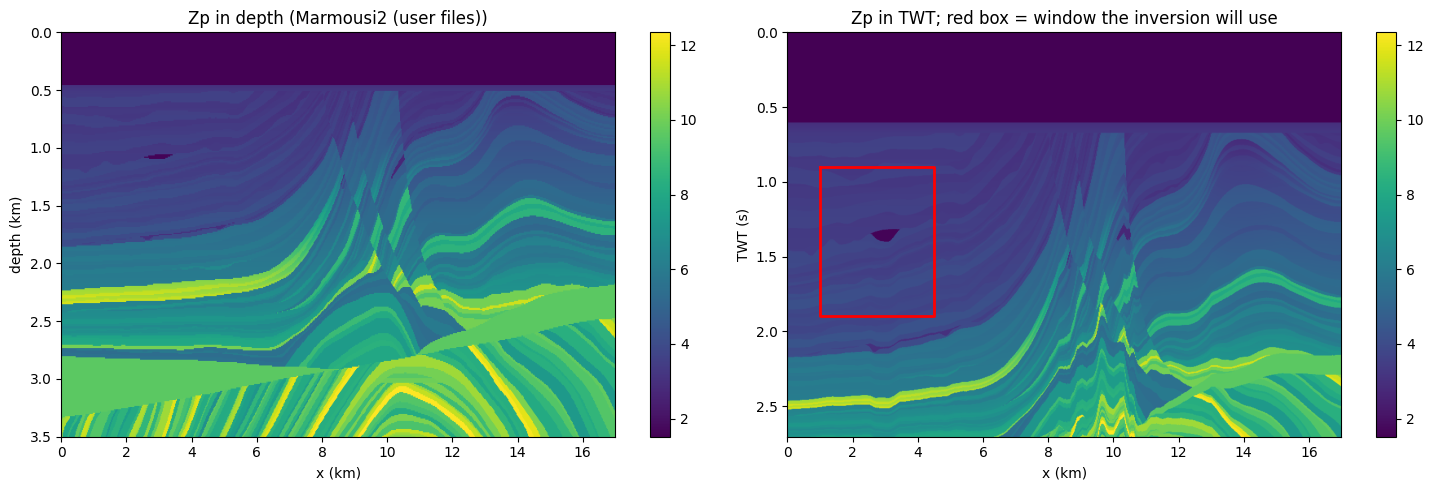

[preview] x 1000-4500 m, TWT 0.90-1.90 s


In [ ]:
QUICK = False            # True = smoke test (rough numbers, a few minutes)
VP_FILE  = "MODEL_P-WAVE_VELOCITY_1.25m.segy"   # must match the name in the Files panel exactly
RHO_FILE = "MODEL_DENSITY_1.25m.segy"
X0, X1   = 1000, 4500      # section start/end (m)
T_START  = 0.9             # window start TWT (s); window is 1.0 s long
SEED     = 0               # seed 0 matches the E2 reference numbers; other seeds also run a fresh baseline
RUN_BASELINE = True        # True = also rerun the unperturbed case in this notebook (+12 min)
MODEL = "standin" if QUICK else "real"

assert VP_FILE or QUICK, "set VP_FILE to your Marmousi2 Vp file (otherwise this would run on the stand-in model)"
BASE = ["--model", MODEL, "--seed", str(SEED), "--x0", str(X0), "--x1", str(X1), "--t_start", str(T_START), "--skip_ens"]
if VP_FILE:
    BASE += ["--vp_file", VP_FILE, "--dz", "1.25", "--dx", "1.25"]
    if RHO_FILE:
        BASE += ["--rho_file", RHO_FILE]
if QUICK:
    BASE += ["--quick"]
preview_model(get_args(BASE + ["--out", "e34_preview"]))   # red box = window used by every run below

## Run E3 and E4 (about 1 hour)

In [ ]:
import json, time
EXPS = {
    "E3a_shift_p10":    ["--bg_shift", "0.10"],
    "E3b_shift_m10":    ["--bg_shift", "-0.10"],
    "E3c_slope_x1.3":   ["--bg_slope_scale", "1.3"],
    "E4a_wavelet_20Hz": ["--fm_inv", "20"],
    "E4b_wavelet_30Hz": ["--fm_inv", "30"],
}
RUN = list(EXPS)           # e.g. RUN = ["E3a_shift_p10"] to run only one
# E2 seed 0, correct background and wavelet (from the earlier E2 run, same settings)
REF = {"Background": dict(corr=0.595, mae=0.873, corr_hp=-0.021), "MAP": dict(corr=0.689, mae=0.827, corr_hp=0.793),
       "VI": dict(corr=0.672, mae=0.875, corr_hp=0.757, picp90=0.75, width90=2.68)}
need_baseline = RUN_BASELINE or QUICK or SEED != 0
todo = (["baseline"] if need_baseline else []) + RUN
summary = {}
if not need_baseline:
    summary["E2 reference"] = REF

def show(summary):
    print(f"{'experiment':18s} | {'BG corr':>7s} {'BG MAE':>6s} | {'MAP corr':>8s} {'MAE':>6s} {'hp':>5s} | {'VI corr':>7s} {'MAE':>6s} {'hp':>5s} {'PICP90':>6s} {'width':>6s}")
    for k, r in summary.items():
        print(f"{k:18s} | {r['Background']['corr']:7.3f} {r['Background']['mae']:6.3f} | "
              f"{r['MAP']['corr']:8.3f} {r['MAP']['mae']:6.3f} {r['MAP']['corr_hp']:5.2f} | "
              f"{r['VI']['corr']:7.3f} {r['VI']['mae']:6.3f} {r['VI']['corr_hp']:5.2f} {r['VI']['picp90']:6.2f} {r['VI']['width90']:6.2f}")

for name in todo:
    t0 = time.time()
    print("=" * 20, name, "=" * 20)
    extra = [] if name == "baseline" else EXPS[name]
    r = run(get_args(BASE + extra + ["--out", "e34_" + name]))
    summary[name] = {k: r[k] for k in ["Background", "MAP", "VI"]}
    json.dump({k: {m: {x: y for x, y in v.items() if x != "coverage" and not x.startswith("elbo")} for m, v in d.items()} for k, d in summary.items()},
              open("e34_summary.json", "w"), indent=1)
    print(f"[done {name} in {time.time() - t0:.0f}s]")
print()
show(summary)

==================== baseline ====================
[model] your files: nz=2801 nx=13601  dz=1.25 m dx=1.25 m  Vp 1028-4700 m/s  rho 1010-2627 kg/m3  depth 3501 m  width 17001 m
[model] water column about 0.67 s TWT; model reaches 3.13 s; window 0.90-1.90 s
[model] Marmousi2 (user files): 120 traces x 250 samples, Zp 1.6-4.2 MRayl
[data ] std(d)=0.0332 noise=0.05*std  sigma_d=0.0033  operator mismatch=0.143
[net  ] parameters=897   prior-predictive std(delta ln Zp)=0.204
[BG   ] corr=0.515 R2=0.263 MAE=0.162
[MAP  ] corr=0.657 R2=0.043 MAE=0.254 resid-corr=0.572 (102s)
[VI   ] corr=0.631 R2=0.383 MAE=0.148 resid-corr=0.518 PICP90=0.98 width90=1.65 (709s)

E2 summary
method        corr      R2     MAE  corr_hp  corr_lp  PICP90  width90
Background   0.515   0.263   0.162    0.011    0.579       -        -
MAP          0.657   0.043   0.254    0.829    0.604       -        -
VI           0.631   0.383   0.148    0.777    0.589    0.98     1.65

Saved to /content/e34_baseline
[done baseline

## How to read the table
- **corr_hp**: correlation of the high-frequency part (the detail the seismic can resolve). If it stays high while MAE rises, the background error only shifts the result.
- **PICP90**: ideal 0.90. If it drops when the background is wrong, the uncertainty is overconfident (dangerous). If the width grows instead, the interval is honest about the extra error.
- **E4**: if the wavelet is wrong, the detail (corr_hp) is expected to suffer more than the background.